# Trabajo Final Integrador: Herramientas Básicas para el Análisis de Datos

**Profesora:** Virginia Marich

**Alumno/a:** Natalia Sabrina Bernardelli

## Pregunta principal:

¿Qué resultados obtienen las marcas de café y los distintos formatos de tienda en cuanto a volumen de ventas, precios y rentabilidad operativa estimada en las distintas ciudades de Indonesia?

Subpreguntas
1. ¿Qué marcas de café generan el mayor volumen de ventas diario?
2. ¿Cómo se relacionan los precios y los descuentos con los resultados de ventas?
3. ¿Qué formatos de tienda presentan los márgenes operativos estimados más elevados?
4. ¿Cómo varía el rendimiento empresarial de una ciudad a otra?

In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving indonesia_coffee_chain_wars_enriched_2026.csv to indonesia_coffee_chain_wars_enriched_2026.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('indonesia_coffee_chain_wars_enriched_2026.csv')

In [ ]:
df.head()
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13000 entries, 0 to 12999
Data columns (total 26 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   store_transaction_id                  13000 non-null  object 
 1   coffee_brand                          13000 non-null  object 
 2   city_location                         13000 non-null  object 
 3   store_format                          13000 non-null  object 
 4   competitor_density_500m               13000 non-null  int64  
 5   base_price_idr                        13000 non-null  int64  
 6   discount_voucher_pct                  13000 non-null  float64
 7   order_method                          13000 non-null  object 
 8   daily_cups_sold                       13000 non-null  int64  
 9   customer_review_rating                13000 non-null  float64
 10  coffee_beans_type                     13000 non-null  object 
 11  store_amenities

,competitor_density_500m,base_price_idr,discount_voucher_pct,daily_cups_sold,customer_review_rating,dwell_time_minutes,net_discounted_price_idr,daily_revenue_estimate_idr,revenue_per_competitor_density,price_competitiveness_ratio,dwell_time_to_spend_ratio,cannibalization_risk_index,customer_price_sensitivity_score,outlet_operating_margin_estimate_pct,confidence_score
count,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,1.300000e+04,1.300000e+04,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000,13000.000000
mean,5.127000,20225.615385,25.694923,575.976154,4.517423,19.169231,15170.141692,8.070648e+06,1.680790e+06,0.750070,1.470100,4.689548,5.514412,29.510046,0.974991
std,2.782764,5568.498474,11.767489,216.870188,0.421443,29.628499,4993.145051,2.701866e+06,1.264295e+06,0.246965,2.603984,1.193801,1.685853,6.584099,0.019631
min,0.000000,9000.000000,0.000000,65.000000,3.000000,5.000000,4086.000000,7.580300e+05,9.850800e+04,0.205000,0.170000,0.970000,1.380000,12.800000,0.903000
25%,3.000000,16000.000000,16.900000,412.000000,4.000000,7.000000,11555.000000,6.116684e+06,9.260940e+05,0.564000,0.460000,3.860000,4.330000,24.800000,0.966000
50%,5.000000,20000.000000,25.100000,550.000000,4.500000,10.000000,15400.000000,7.867285e+06,1.341040e+06,0.759000,0.670000,4.635000,5.470000,29.500000,0.985000
75%,7.000000,24000.000000,34.025000,729.000000,5.000000,13.000000,18492.000000,9.806303e+06,2.005216e+06,0.915000,1.120000,5.470000,6.690000,34.100000,0.990000
max,14.000000,38000.000000,55.000000,1250.000000,5.000000,240.000000,31746.000000,1.999788e+07,1.802640e+07,1.609000,35.020000,8.840000,10.000000,45.000000,0.990000


In [ ]:
df.isna().sum()

,0
store_transaction_id,0
coffee_brand,0
city_location,0
store_format,0
competitor_density_500m,0
base_price_idr,0
discount_voucher_pct,0
order_method,0
daily_cups_sold,0
customer_review_rating,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.corr(numeric_only=True)

,competitor_density_500m,base_price_idr,discount_voucher_pct,daily_cups_sold,customer_review_rating,dwell_time_minutes,net_discounted_price_idr,daily_revenue_estimate_idr,revenue_per_competitor_density,price_competitiveness_ratio,dwell_time_to_spend_ratio,cannibalization_risk_index,customer_price_sensitivity_score,outlet_operating_margin_estimate_pct,confidence_score
competitor_density_500m,1.000000,0.017582,-0.010021,0.073637,-0.059939,-0.007368,0.018522,0.107575,-0.633193,0.008068,-0.014136,0.810173,-0.048209,-0.096158,-0.193412
base_price_idr,0.017582,1.000000,-0.215931,-0.594243,0.025106,0.001679,0.891310,0.300147,0.124188,0.884257,-0.204916,-0.079508,-0.525520,0.102324,-0.145580
discount_voucher_pct,-0.010021,-0.215931,1.000000,0.345132,0.062904,0.039047,-0.618869,-0.339679,-0.143888,-0.622136,0.190179,0.417419,0.710808,-0.765589,0.436296
daily_cups_sold,0.073637,-0.594243,0.345132,1.000000,0.036755,0.028726,-0.615999,0.412196,0.150846,-0.621414,0.180444,0.314565,0.398157,-0.514593,0.161330
customer_review_rating,-0.059939,0.025106,0.062904,0.036755,1.000000,0.016457,-0.007792,0.010136,0.029621,-0.011635,0.028802,-0.023364,0.032791,-0.105101,0.190748
dwell_time_minutes,-0.007368,0.001679,0.039047,0.028726,0.016457,1.000000,-0.015938,0.008559,0.005783,-0.015422,0.888082,0.022630,0.114264,-0.050924,-0.001604
net_discounted_price_idr,0.018522,0.891310,-0.618869,-0.615999,-0.007792,-0.015938,1.000000,0.399236,0.166741,0.995523,-0.240960,-0.249555,-0.741212,0.418124,-0.320835
daily_revenue_estimate_idr,0.107575,0.300147,-0.339679,0.412196,0.010136,0.008559,0.399236,1.000000,0.391540,0.386516,-0.090873,0.061928,-0.386435,-0.047910,-0.188926
revenue_per_competitor_density,-0.633193,0.124188,-0.143888,0.150846,0.029621,0.005783,0.166741,0.391540,1.000000,0.169397,-0.031903,-0.515592,-0.150804,0.016491,0.042550
price_competitiveness_ratio,0.008068,0.884257,-0.622136,-0.621414,-0.011635,-0.015422,0.995523,0.386516,0.169397,1.000000,-0.239125,-0.259234,-0.740578,0.422569,-0.320198


In [ ]:
df.isna().sum()

,0
store_transaction_id,0
coffee_brand,0
city_location,0
store_format,0
competitor_density_500m,0
base_price_idr,0
discount_voucher_pct,0
order_method,0
daily_cups_sold,0
customer_review_rating,0


In [ ]:
df.columns = df.columns.str.strip().str.lower()

In [ ]:
df['daily_revenue_estimate_idr'].dtype

dtype('float64')

In [ ]:
df['daily_revenue_estimate_idr'].head()

,daily_revenue_estimate_idr
0,10459710.0
1,14123270.0
2,7854302.0
3,7579008.0
4,13394688.0


In [ ]:
df['store_transaction_id'].duplicated().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.columns = df.columns.str.strip().str.lower()

In [ ]:
print("Missing values:")
display(df.isna().sum())

Missing values:


,0
store_transaction_id,0
coffee_brand,0
city_location,0
store_format,0
competitor_density_500m,0
base_price_idr,0
discount_voucher_pct,0
order_method,0
daily_cups_sold,0
customer_review_rating,0


In [ ]:
print("Revenue data type:")
print(df['daily_revenue_estimate_idr'].dtype)


Revenue data type:
float64


In [ ]:
print("Exact duplicates:", df.duplicated().sum())
print("Duplicate transaction IDs:",
      df['store_transaction_id'].duplicated().sum())

Exact duplicates: 0
Duplicate transaction IDs: 0


In [ ]:
print("\nCleaned dataset preview:")
display(df.head())


Cleaned dataset preview:


,store_transaction_id,coffee_brand,city_location,store_format,competitor_density_500m,base_price_idr,discount_voucher_pct,order_method,daily_cups_sold,customer_review_rating,...,revenue_per_competitor_density,price_competitiveness_ratio,dwell_time_to_spend_ratio,cannibalization_risk_index,customer_price_sensitivity_score,outlet_operating_margin_estimate_pct,customer_brand_loyalty_tier,primary_brand_switch_driver,cot_retail_dynamics_rationale,confidence_score
0,ID_COF_04E8960997,Fore Coffee,Bali Badung,Mall Kiosk,2,31000,31.0,Dine-In POS Cashier,489,5.0,...,3486570.0,1.086,6.45,4.02,5.92,21.2,Promo-Chaser-Opportunist,Cheaper-Competitor-Opening,Gerai/transaksi 'ID_COF_04E8960997' dari jarin...,0.962
1,ID_COF_11C2B7E56B,Fore Coffee,Bali Badung,Standalone Shophouse / Ruko,0,35000,22.1,Mobile App Pickup,518,4.0,...,14123270.0,1.384,0.51,3.15,3.29,30.3,Value-Conscious-Regular,Taste-Inconsistency-Drop,Gerai/transaksi 'ID_COF_11C2B7E56B' dari jarin...,0.989
2,ID_COF_13E6C4B1C1,Fore Coffee,Bali Badung,Standalone Shophouse / Ruko,7,29000,29.1,Online Ojol Delivery,382,5.0,...,981788.0,1.044,0.49,5.85,3.65,27.8,Value-Conscious-Regular,Cheaper-Competitor-Opening,Gerai/transaksi 'ID_COF_13E6C4B1C1' dari jarin...,0.966
3,ID_COF_173255A861,Fore Coffee,Bali Badung,Standalone Shophouse / Ruko,2,27000,18.4,Dine-In POS Cashier,344,4.5,...,2526336.0,1.118,0.68,3.68,5.08,31.6,Value-Conscious-Regular,Lack-Of-Seating-WiFi,Gerai/transaksi 'ID_COF_173255A861' dari jarin...,0.984
4,ID_COF_26F9915A2A,Fore Coffee,Bali Badung,Office Tower Lobby,2,32000,14.4,Online Ojol Delivery,489,4.5,...,4464896.0,1.391,0.26,3.11,2.04,29.0,Die-Hard-Loyalist,Voucher-Exhaustion-Price-Hike,Gerai/transaksi 'ID_COF_26F9915A2A' dari jarin...,0.951


In [ ]:
categorical_columns = df.select_dtypes(
    include=['object']
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print("Leading/trailing spaces:",
          (df[col].dropna() != df[col].dropna().str.strip()).sum())
    print(df[col].value_counts().head(10))


store_transaction_id
Unique values: 13000
Leading/trailing spaces: 0
store_transaction_id
ID_COF_04E8960997    1
ID_COF_11C2B7E56B    1
ID_COF_13E6C4B1C1    1
ID_COF_173255A861    1
ID_COF_26F9915A2A    1
ID_COF_2BF33944D9    1
ID_COF_2E5968D54E    1
ID_COF_2EA2B79D3A    1
ID_COF_2EAFCC4543    1
ID_COF_2EE2584DD6    1
Name: count, dtype: int64

coffee_brand
Unique values: 5
Leading/trailing spaces: 0
coffee_brand
Tomoro Coffee      4011
Kopi Kenangan      3510
Fore Coffee        2420
Point Coffee       1709
Kopi Janji Jiwa    1350
Name: count, dtype: int64

city_location
Unique values: 16
Leading/trailing spaces: 0
city_location
Jakarta Selatan      2254
Jakarta Pusat        1724
Surabaya             1502
Bandung              1391
Jakarta Barat        1388
Tangerang Selatan    1136
Bekasi                903
Medan                 689
Depok                 564
Semarang              535
Name: count, dtype: int64

store_format
Unique values: 5
Leading/trailing spaces: 0
store_format
Stand

In [ ]:
base_path = "/content/drive/MyDrive/Colab Notebooks/"
output_path = base_path + 'indonesia_coffee_chain_wars_clean.csv'
df.to_csv(output_path, index=False)

print("Dataset successfully exported to:", output_path)

Dataset successfully exported to: /content/drive/MyDrive/Colab Notebooks/indonesia_coffee_chain_wars_clean.csv


### Resumen de la limpieza de datos

**Conjunto de datos:** Indonesia Coffee Chain Wars (Enriquecido 2026)

**1. Valores perdidos**
- No se detectaron valores perdidos en el conjunto de datos.
- No fue necesario realizar ninguna imputación.

**2. Nombres de columnas y tipos de datos**
- Se estandarizaron los nombres de las columnas a minúsculas y se eliminaron espacios en blanco.
- La columna `daily_revenue_estimate_idr` ya era numérica (`float64`) y estaba expresada en rupias indonesias (IDR).
- No fue necesaria ninguna conversión de ingresos.
- No se crearon columnas adicionales.

**3. Registros duplicados**
- No se encontraron registros duplicados exactos.
- No se detectaron ID de transacciones duplicados (`store_transaction_id`).
- No se eliminó ningún registro.

**4. Estandarización de datos adicionales**

*   **Estandarización de fechas:**
    *   No se encontraron columnas de fecha en el conjunto de datos.
    *   No fue necesario realizar ninguna conversión de fechas.

*   **Estandarización de datos categóricos:**
    *   Se revisaron todas las columnas categóricas en busca de valores incoherentes y espacios en blanco al principio o al final.
    *   No se identificaron incoherencias significativas.
    *   Se conservaron las etiquetas de categoría existentes.

*   **Estandarización de unidades:**
    *   Los valores monetarios ya se expresaban de forma coherente en rupias indonesias (IDR).
    *   Las columnas de porcentajes ya se representaban en una escala de 0 a 100.
    *   Las medidas de tiempo se expresaban en minutos.
    *   El volumen de ventas se expresaba en tazas al día.
    *   No fue necesario realizar ninguna conversión de unidades.

**En resumen:** No se requirieron transformaciones adicionales tras las comprobaciones de estandarización.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

%matplotlib inline

# Ventas promedio por marca de café

*¿Qué marca registra el mayor volumen promedio de ventas diarias?*

Tomoro Coffee presenta el mayor promedio de ventas, con aproximadamente 798 tazas diarias por registro. Kopi Janji Jiwa presenta el menor promedio, con aproximadamente 370.

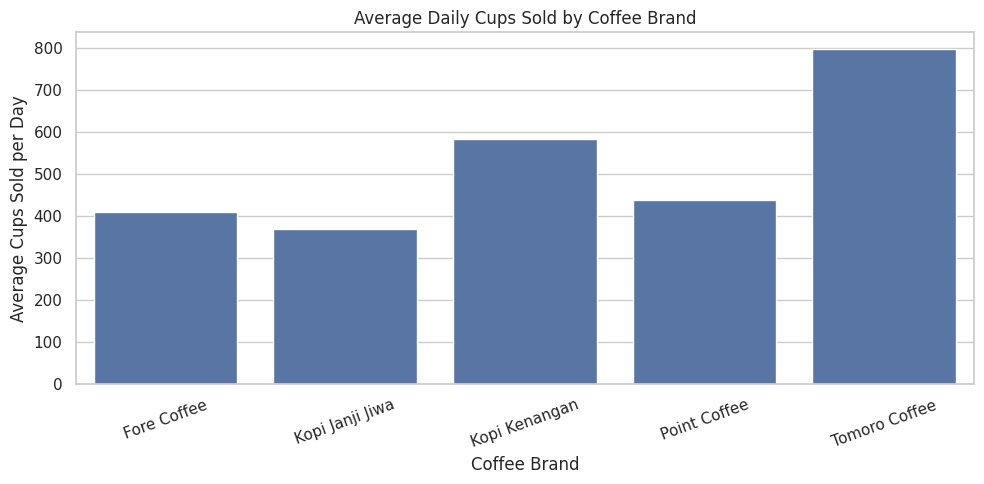

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='coffee_brand',
    y='daily_cups_sold',
    estimator='mean',
    errorbar=None
)

plt.title('Average Daily Cups Sold by Coffee Brand')
plt.xlabel('Coffee Brand')
plt.ylabel('Average Cups Sold per Day')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Distribución de ventas diarias

*¿Cómo se distribuye el volumen de ventas diarias entre los registros?*

Se presenta un promedio de aproximadamente 576 tazas diarias y una mediana de 550.

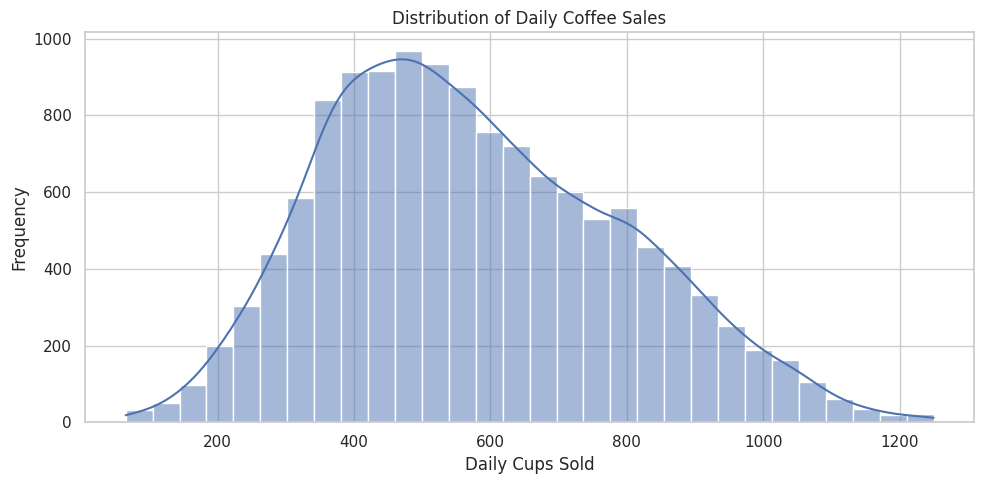

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='daily_cups_sold',
    bins=30,
    kde=True
)

plt.title('Distribution of Daily Coffee Sales')
plt.xlabel('Daily Cups Sold')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Precio y volumen de ventas

*¿Existe una relación entre el precio de venta y la cantidad de tazas vendidas?*

Los registros con precios más elevados tienden a presentar menores volúmenes de venta. Sin embargo, una correlación no demuestra causalidad, también pueden intervenir otros factores, como la marca, la ubicación y el formato del establecimiento.

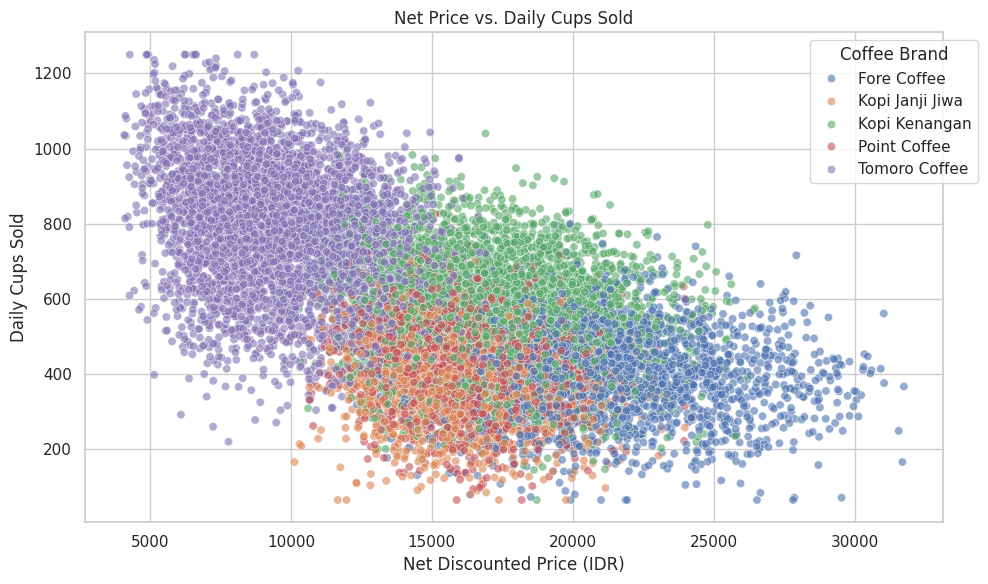

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='net_discounted_price_idr',
    y='daily_cups_sold',
    hue='coffee_brand',
    alpha=0.6
)

plt.title('Net Price vs. Daily Cups Sold')
plt.xlabel('Net Discounted Price (IDR)')
plt.ylabel('Daily Cups Sold')
plt.legend(title='Coffee Brand', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Ventas según el formato del establecimiento

*¿Qué formatos de cafetería presentan mayores volúmenes de ventas?*

Los establecimientos ubicados en oficinas (Office Tower Lobby) presentan una mediana de aproximadamente 655 tazas diarias, mientras que las cocinas exclusivamente de delivery (Cloud Kitchen) presentan una mediana de 373.

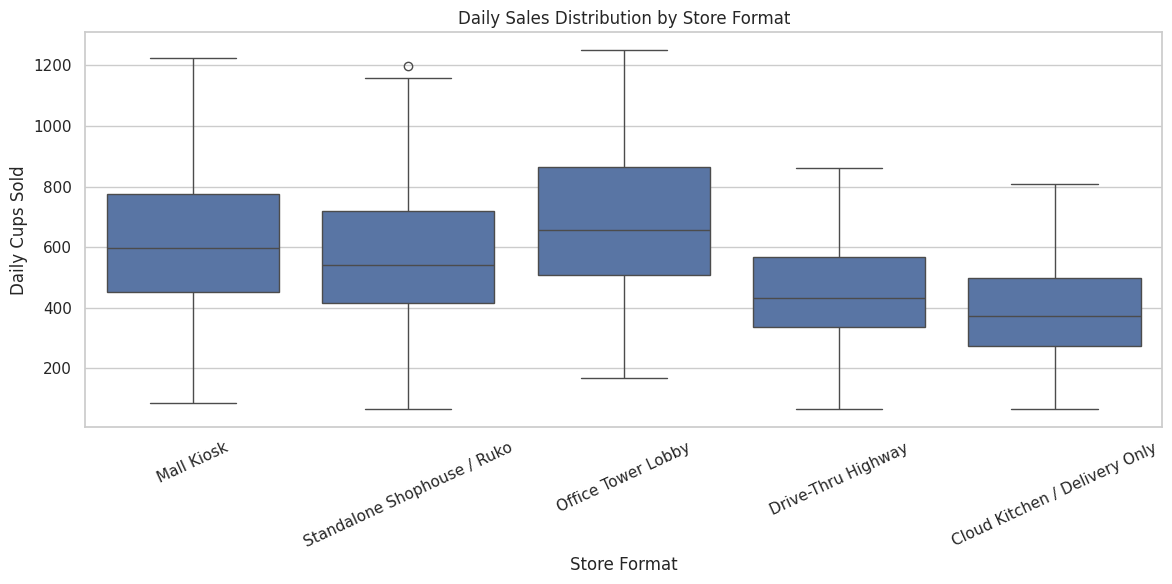

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='store_format',
    y='daily_cups_sold'
)

plt.title('Daily Sales Distribution by Store Format')
plt.xlabel('Store Format')
plt.ylabel('Daily Cups Sold')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()